# T46 · Sensibilidad del consumo sobre la recarga

**Pregunta.** ¿Qué hipótesis del modelo de consumo cambian la estación que más energía pide, su energía diaria o el pico de potencia de la red?

Se mueve un parámetro cada vez entre los extremos de `consumo/config.yaml` y el resto queda en el caso central de T41–T43. En cada caso se vuelve a resolver la escala de rodadura y aire para que el ajuste dé 13,5 Wh/km, así que cambia el reparto de la energía entre viajes y estaciones, no el total. El último contraste mueve el propio coeficiente de referencia un ±20 %: no es un rango medido, sirve para comparar su peso con el de la física. Las llegadas son las de la red elegida en T44 y la potencia de cada sesión es la de T44 (576 Wh / 7 h).

La regeneración no se incluye: con un solo tramo neto por viaje, un viaje que baja ya queda sin tracción y la regeneración no cambia nada.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from comun.figuras import guardar_figura, plt
from comun.web import exportar
from sensibilidad import publicar_sensibilidad

t = publicar_sensibilidad()
columnas = ["factor", "valor", "periodo", "k", "fisico_wh_km", "kwh_dia", "estacion_max", "estacion_max_kwh_dia",
            "estacion_max_p95_kwh", "pico_red_kw", "spearman_central", "comunes_top10", "misma_estacion_max"]
display(t[columnas].round(3))

,factor,valor,periodo,k,fisico_wh_km,kwh_dia,estacion_max,estacion_max_kwh_dia,estacion_max_p95_kwh,pico_red_kw,spearman_central,comunes_top10,misma_estacion_max
0,Caso central,central,ajuste,1.859,7.548,16.609,891e8052a23ffff,0.295,0.573,3.229,1.000,10,True
1,Caso central,central,reservada,1.859,7.548,18.764,891e8050cd3ffff,0.425,0.569,2.977,1.000,10,True
2,Coeficiente de rodadura,0.01,ajuste,2.479,5.845,16.603,891e8052a23ffff,0.299,0.571,3.195,0.999,10,True
3,Coeficiente de rodadura,0.01,reservada,2.479,5.845,18.759,891e8050cd3ffff,0.427,0.565,2.901,0.999,8,True
4,Coeficiente de rodadura,0.02,ajuste,1.487,9.272,16.613,891e8052a23ffff,0.292,0.574,3.245,1.000,10,True
5,Coeficiente de rodadura,0.02,reservada,1.487,9.272,18.768,891e8050cd3ffff,0.424,0.573,3.038,1.000,10,True
6,Área aerodinámica CdA (m²),0.4,ajuste,1.994,7.080,16.614,891e8052a23ffff,0.291,0.574,3.247,1.000,10,True
7,Área aerodinámica CdA (m²),0.4,reservada,1.994,7.080,18.768,891e8050cd3ffff,0.424,0.573,3.044,1.000,10,True
8,Área aerodinámica CdA (m²),0.7,ajuste,1.740,8.017,16.605,891e8052a23ffff,0.297,0.572,3.209,1.000,10,True
9,Área aerodinámica CdA (m²),0.7,reservada,1.740,8.017,18.761,891e8050cd3ffff,0.426,0.567,2.921,1.000,9,True


## Tornado

Cada barra va del menor al mayor cambio respecto al caso central en el ajuste. La izquierda mide la energía diaria de la estación que más recibe y la derecha el pico simultáneo de la red. Los puntos rojos marcan los casos en que la estación con más energía deja de ser la del caso central.

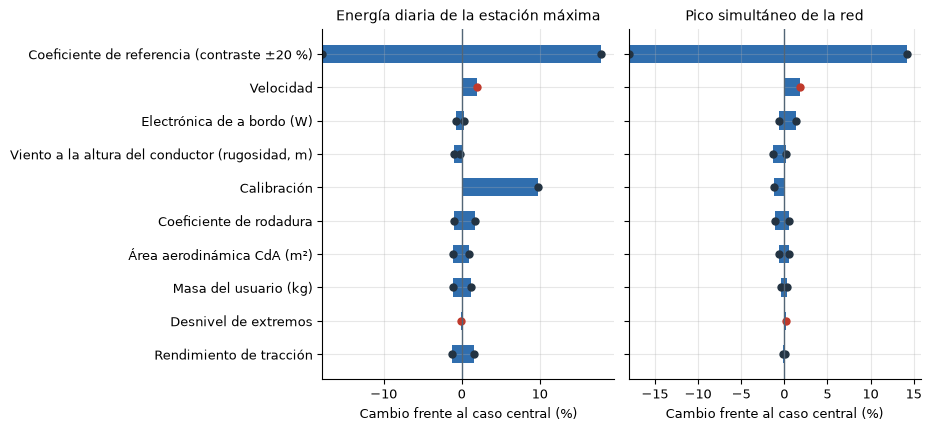

In [2]:
aj = t.loc[t["periodo"].eq("ajuste") & t["factor"].ne("Caso central")]
orden = (aj.groupby("factor")["cambio_pico_red_kw_pct"].agg(lambda x: x.abs().max())
         .sort_values().index.tolist())
fig, ejes = plt.subplots(1, 2, figsize=(9.2, 4.2), sharey=True, layout="constrained")
for eje, col, titulo in zip(ejes, ("cambio_estacion_max_kwh_dia_pct", "cambio_pico_red_kw_pct"),
                            ("Energía diaria de la estación máxima", "Pico simultáneo de la red")):
    for y, factor in enumerate(orden):
        g = aj.loc[aj["factor"].eq(factor)]
        lo, hi = min(g[col].min(), 0), max(g[col].max(), 0)
        eje.barh(y, hi - lo, left=lo, height=.55, color="#306eae")
        for r in g.itertuples():
            eje.plot(getattr(r, col), y, "o", ms=5, color="#233342" if r.misma_estacion_max else "#c0392b")
    eje.axvline(0, color="#526576", lw=1)
    eje.set(title=titulo, xlabel="Cambio frente al caso central (%)")
ejes[0].set_yticks(range(len(orden)), orden)
guardar_figura(fig, "consumo", "T46_tornado")

In [3]:
aj, res = (t.loc[t["periodo"].eq(p)] for p in ("ajuste", "reservada"))
fisicos = t.loc[~t["parametro"].isin(["central", "referencia_relativa", "calibracion"])]
cambia = sorted(set(t.loc[~t["misma_estacion_max"] & t["parametro"].ne("referencia_relativa"), "factor"]))
ref = aj.loc[aj["parametro"].eq("referencia_relativa")]
c_aj = aj.loc[aj["parametro"].eq("central")].iloc[0]
c_res = res.loc[res["parametro"].eq("central")].iloc[0]
exportar("fase2", "sensibilidad", {"tornado": t, "central": {"ajuste": c_aj["estacion_max"], "reservada": c_res["estacion_max"]}})
display(Markdown(f"""## Conclusiones
- Con la escala recalibrada, los parámetros físicos mueven la energía diaria de la estación máxima como mucho un **{fisicos['cambio_estacion_max_kwh_dia_pct'].abs().max():.1f} %** y el pico de la red un **{fisicos['cambio_pico_red_kw_pct'].abs().max():.1f} %**. El orden de las estaciones apenas cambia: el Spearman con el caso central no baja de **{fisicos['spearman_central'].min():.3f}**.
- La estación con más energía es **{c_aj.estacion_max}** en el ajuste ({c_aj.estacion_max_kwh_dia:.3f} kWh/día) y **{c_res.estacion_max}** en la semana reservada ({c_res.estacion_max_kwh_dia:.3f} kWh/día). Solo cambia en algún periodo con: {', '.join(cambia).lower()}.
- Lo que más pesa es el coeficiente de referencia: un ±20 % mueve el pico de la red del ajuste de **{ref['pico_red_kw'].min():.2f} a {ref['pico_red_kw'].max():.2f} kW** y la energía de la estación máxima en la misma proporción. El dimensionado de la fase 3 debe probar ese margen; los coeficientes físicos apenas lo mueven."""))

## Conclusiones
- Con la escala recalibrada, los parámetros físicos mueven la energía diaria de la estación máxima como mucho un **2.4 %** y el pico de la red un **10.0 %**. El orden de las estaciones apenas cambia: el Spearman con el caso central no baja de **0.979**.
- La estación con más energía es **891e8052a23ffff** en el ajuste (0.295 kWh/día) y **891e8050cd3ffff** en la semana reservada (0.425 kWh/día). Solo cambia en algún periodo con: calibración, desnivel de extremos, velocidad.
- Lo que más pesa es el coeficiente de referencia: un ±20 % mueve el pico de la red del ajuste de **2.65 a 3.69 kW** y la energía de la estación máxima en la misma proporción. El dimensionado de la fase 3 debe probar ese margen; los coeficientes físicos apenas lo mueven.